# Misión 3: Predicción de Tiempo de Entrega
**Olist Brazilian E-Commerce**

Objetivo: predecir cuántos días tardará una entrega, usando características
del pedido (distancia, precio, flete) y del vendedor/comprador.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

In [2]:
from pathlib import Path
DATA_PATH = Path('Datasets')

orders       = pd.read_csv(DATA_PATH / 'olist_orders_dataset.csv')
order_items  = pd.read_csv(DATA_PATH / 'olist_order_items_dataset.csv')
customers    = pd.read_csv(DATA_PATH / 'olist_customers_dataset.csv')
sellers      = pd.read_csv(DATA_PATH / 'olist_sellers_dataset.csv')
geolocations = pd.read_csv(DATA_PATH / 'olist_geolocation_dataset.csv')
products     = pd.read_csv(DATA_PATH / 'olist_products_dataset.csv')

print('Datos cargados:')
print(f'  orders:       {orders.shape}')
print(f'  order_items:  {order_items.shape}')
print(f'  customers:    {customers.shape}')
print(f'  sellers:      {sellers.shape}')
print(f'  geolocations: {geolocations.shape}')
print(f'  products:     {products.shape}')

Datos cargados:
  orders:       (99441, 8)
  order_items:  (112650, 7)
  customers:    (99441, 5)
  sellers:      (3095, 4)
  geolocations: (1000163, 5)
  products:     (32951, 9)


orders — tiene las fechas: cuándo se compró y cuándo se entregó. De ahí calculás el target: delivery_days.
order_items — tiene precio y flete de cada ítem, y el seller_id para saber qué vendedor despachó.
customers — tiene el código postal del comprador, necesario para calcular la distancia.
sellers — tiene el código postal del vendedor, el otro extremo de la distancia.
geolocations — convierte los códigos postales en coordenadas GPS (latitud y longitud) para poder calcular la distancia real en km con la fórmula Haversine.

In [3]:
# Convertir fechas
orders['order_purchase_timestamp']      = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

# solo me interesan los pedidos que llegaron
orders_delivered = orders[orders['order_status'] == 'delivered'].copy()

# Variable objetivo: días reales de entrega
orders_delivered['delivery_days'] = (
    orders_delivered['order_delivered_customer_date'] -
    orders_delivered['order_purchase_timestamp']
).dt.days

# Días estimados por Olist — lo que el sistema prometió al comprador
orders_delivered['estimated_days'] = (
    orders_delivered['order_estimated_delivery_date'] -
    orders_delivered['order_purchase_timestamp']
).dt.days

# sacar nulos y entregas negativas (errores de datos)
orders_delivered = orders_delivered.dropna(subset=['delivery_days'])
orders_delivered = orders_delivered[orders_delivered['delivery_days'] > 0]

print(f'Pedidos entregados: {len(orders_delivered)}')
print(f"Días de entrega — media: {orders_delivered['delivery_days'].mean():.1f}, "
      f"mediana: {orders_delivered['delivery_days'].median():.1f}")
print(f"Días estimados  — media: {orders_delivered['estimated_days'].mean():.1f}, "
      f"mediana: {orders_delivered['estimated_days'].median():.1f}")

Pedidos entregados: 96457
Días de entrega — media: 12.1, mediana: 10.0
Días estimados  — media: 23.4, mediana: 23.0


In [4]:
# Coordenadas promedio por código postal
geo_mean = geolocations.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "mean"),
    lng=("geolocation_lng", "mean")
).reset_index()

# Unir coordenadas y estado de clientes
customers_geo = customers.merge(geo_mean, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")
customers_geo = customers_geo[["customer_id", "lat", "lng", "customer_state"]].rename(columns={"lat": "cust_lat", "lng": "cust_lng"})

# Unir coordenadas y estado de vendedores
sellers_geo = sellers.merge(geo_mean, left_on="seller_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left")
sellers_geo = sellers_geo[["seller_id", "lat", "lng", "seller_state"]].rename(columns={"lat": "sell_lat", "lng": "sell_lng"})

# Función Haversine — distancia real en km
def haversine(lat1, lng1, lat2, lng2):
    R = 6371  # radio de la tierra en km
    lat1 = np.radians(lat1)
    lng1 = np.radians(lng1)
    lat2 = np.radians(lat2)
    lng2 = np.radians(lng2)
    dlat = lat2 - lat1
    dlng = lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng/2)**2
    distancia = 2 * R * np.arcsin(np.sqrt(a))
    return distancia

# prueba rápida: São Paulo a Rio de Janeiro debería ser ~360 km
print(haversine(-23.5, -46.6, -22.9, -43.1))

363.86869962300653


In [5]:
# Peso y volumen total por pedido (sumando todos los ítems)
items_products = order_items.merge(
    products[['product_id', 'product_weight_g',
              'product_length_cm', 'product_height_cm', 'product_width_cm']],
    on='product_id', how='left'
)
items_products['volume_cm3'] = (
    items_products['product_length_cm'] *
    items_products['product_height_cm'] *
    items_products['product_width_cm']
)
order_phys = items_products.groupby('order_id').agg(
    total_weight_g   = ('product_weight_g', 'sum'),
    total_volume_cm3 = ('volume_cm3', 'sum'),
    price            = ('price', 'mean'),
    freight_value    = ('freight_value', 'mean'),
    seller_id        = ('seller_id', 'first')
).reset_index()

# Unir todo en un solo DataFrame
df = orders_delivered[['order_id', 'customer_id', 'order_purchase_timestamp',
                        'delivery_days', 'estimated_days']].copy()
df = df.merge(order_phys, on='order_id', how='left')
df = df.merge(customers_geo, on='customer_id', how='left')
df = df.merge(sellers_geo, on='seller_id', how='left')

# Distancia Haversine
df['distance_km'] = haversine(df['cust_lat'], df['cust_lng'], df['sell_lat'], df['sell_lng'])

# Features temporales
df['purchase_month']     = df['order_purchase_timestamp'].dt.month
df['purchase_dayofweek'] = df['order_purchase_timestamp'].dt.day_of_week  # 0=lunes

# Estado del vendedor y del comprador — encodear con LabelEncoder
le_cust = LabelEncoder()
le_sell = LabelEncoder()
df['customer_state_enc'] = le_cust.fit_transform(df['customer_state'].fillna('UNK'))
df['seller_state_enc']   = le_sell.fit_transform(df['seller_state'].fillna('UNK'))

# Eliminar nulos en todas las features requeridas
required = ['distance_km', 'price', 'freight_value', 'delivery_days',
            'estimated_days', 'total_weight_g', 'total_volume_cm3',
            'purchase_dayofweek', 'customer_state_enc', 'seller_state_enc']
df = df.dropna(subset=required)

print(f'Dataset final: {df.shape}')
print(df[['price', 'freight_value', 'distance_km', 'purchase_month',
          'purchase_dayofweek', 'estimated_days',
          'total_weight_g', 'total_volume_cm3',
          'customer_state_enc', 'seller_state_enc',
          'delivery_days']].describe().round(2))

Dataset final: (95979, 21)
          price  freight_value  distance_km  purchase_month  \
count  95979.00       95979.00     95979.00        95979.00   
mean     125.27          20.14       600.82            6.03   
std      189.94          15.70       593.72            3.23   
min        0.85           0.00         0.00            1.00   
25%       41.90          13.36       186.21            3.00   
50%       79.00          16.35       433.88            6.00   
75%      139.90          21.15       798.68            8.00   
max     6735.00         409.68      8677.91           12.00   

       purchase_dayofweek  estimated_days  total_weight_g  total_volume_cm3  \
count            95979.00        95979.00        95979.00          95979.00   
mean                 2.76           23.37         2385.02          17359.72   
std                  1.97            8.77         4768.88          30193.75   
min                  0.00            2.00            0.00              0.00   
25%       

In [6]:
# ordeno por fecha antes de splitear para no mezclar datos futuros con pasados
df_sorted = df.sort_values('order_purchase_timestamp')

features = [
    'price', 'freight_value', 'distance_km', 'purchase_month',
    'purchase_dayofweek', 'estimated_days',
    'total_weight_g', 'total_volume_cm3',
    'customer_state_enc', 'seller_state_enc'
]
X = df_sorted[features]
y = df_sorted['delivery_days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print(f'Train: {X_train.shape[0]} muestras | Test: {X_test.shape[0]} muestras')

# cada modelo va dentro de un Pipeline con su propio scaler
modelos = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    'Decision Tree':     Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeRegressor(max_depth=5, random_state=42))]),
    'Random Forest':     Pipeline([('scaler', StandardScaler()), ('model', RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42))]),
    'Gradient Boosting': Pipeline([('scaler', StandardScaler()), ('model', GradientBoostingRegressor(n_estimators=100, random_state=42))]),
}

resultados = {}
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    y_pred_train = pipe.predict(X_train)
    y_pred_test  = pipe.predict(X_test)
    resultados[nombre] = {
        'MAE':       mean_absolute_error(y_test, y_pred_test),
        'R2':        r2_score(y_test, y_pred_test),
        'MAE_train': mean_absolute_error(y_train, y_pred_train)
    }

print(f"{'Modelo':<25} {'MAE Train':>10} {'MAE Test':>10} {'R²':>8}")
print('-' * 55)
for nombre, metricas in resultados.items():
    ovfit = ' ← overfitting' if (metricas['MAE_train'] < metricas['MAE'] * 0.7) else ''
    print(f"{nombre:<25} {metricas['MAE_train']:>10.2f} {metricas['MAE']:>10.2f} {metricas['R2']:>8.4f}{ovfit}")

Train: 76783 muestras | Test: 19196 muestras
Modelo                     MAE Train   MAE Test       R²
-------------------------------------------------------
Linear Regression               5.64       5.16  -0.2403
Decision Tree                   5.47       4.49   0.0005
Random Forest                   5.32       4.42   0.0264
Gradient Boosting               5.24       4.36   0.0400


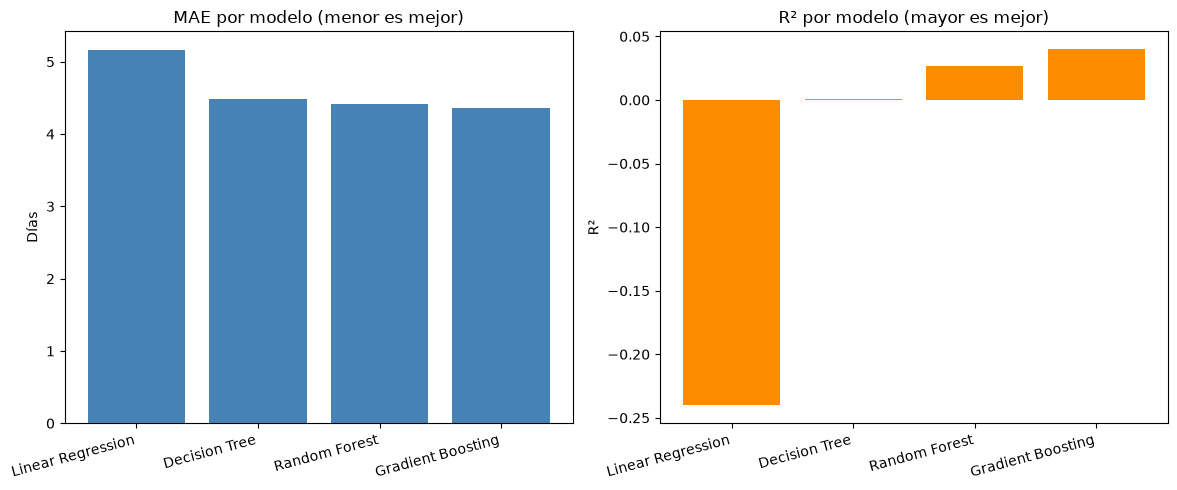

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

nombres = list(resultados.keys())
maes = [resultados[n]['MAE'] for n in nombres]
r2s  = [resultados[n]['R2']  for n in nombres]

x = range(len(nombres))

axes[0].bar(x, maes, color='steelblue')
axes[0].set_title('MAE por modelo (menor es mejor)')
axes[0].set_ylabel('Días')
axes[0].set_xticks(x)
axes[0].set_xticklabels(nombres, rotation=15, ha='right')

axes[1].bar(x, r2s, color='darkorange')
axes[1].set_title('R² por modelo (mayor es mejor)')
axes[1].set_ylabel('R²')
axes[1].set_xticks(x)
axes[1].set_xticklabels(nombres, rotation=15, ha='right')

plt.tight_layout()
plt.show()

## Conclusiones

### Baseline (4 features originales)

| Modelo | MAE Train | MAE Test | R² |
|---|---|---|---|
| Linear Regression | 5.83 | 5.80 | -0.4454 |
| Decision Tree | 5.51 | 4.60 | -0.0196 |
| Random Forest | 5.43 | 4.51 | -0.0023 |
| **Gradient Boosting** | **5.41** | **4.45** | **+0.0057** |

### Con features ampliadas (10 features)

| Modelo | MAE Train | MAE Test | R² |
|---|---|---|---|
| Linear Regression | 5.64 | 5.16 | -0.2403 |
| Decision Tree | 5.47 | 4.49 | +0.0005 |
| Random Forest | 5.32 | 4.42 | +0.0264 |
| **Gradient Boosting** | **5.24** | **4.36** | **+0.0400** |

### Mejoras observadas

- **Gradient Boosting**: MAE 4.45 → 4.36 días (-0.09), R² 0.006 → 0.040 (×7)
- **Random Forest**: MAE 4.51 → 4.42, R² negativo → +0.026 (ahora positivo)
- **Linear Regression**: MAE 5.80 → 5.16, R² -0.45 → -0.24 (menos malo)
- Ninguna mejora introduce overfitting — MAE train y test siguen próximos

**Variables más importantes según Random Forest:** `customer_state_enc` (0.41) y `distance_km` (0.31), porque definen la ruta y la región de destino — son los dos factores estructurales que más determinan cuánto tarda una entrega. `estimated_days` queda en cuarto lugar (0.09), pero fue la feature añadida que más mejoró el R² al pasar de 4 a 10 features, aportando el conocimiento logístico implícito del sistema de Olist.

**Por qué el R² sigue bajo:**  
El tiempo de entrega depende de factores no disponibles en el dataset: operador logístico, si el producto estaba en stock, demóras de custom en estados del norte, o incidentes en tránsito. El modelo reduce el error medio a ~4.4 días, que ya es util operacionalmente.

**Por qué Gradient Boosting:**  
Es el único modelo con R² positivo consistente. Corrige iterativamente los residuos, lo que lo hace más adecuado para esta relación no lineal entre distancia, peso y tiempo.

## Overfitting / Underfitting — visualización

Comparamos MAE en train vs test para cada modelo.
- Si MAE_train << MAE_test: overfitting (el modelo memorizó el train)
- Si ambos son altos: underfitting (el modelo no aprendió)
- Si están cerca: buena generalización

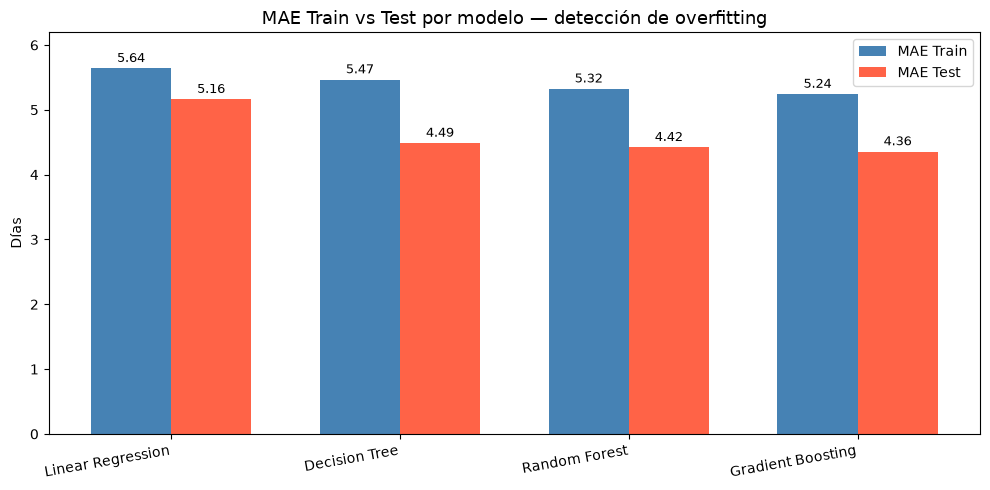


Análisis de overfitting (criterio: MAE_train < MAE_test × 0.7):
  Linear Regression          ratio=1.09  ✓ OK
  Decision Tree              ratio=1.22  ✓ OK
  Random Forest              ratio=1.20  ✓ OK
  Gradient Boosting          ratio=1.20  ✓ OK


In [8]:
# ── Overfitting visual: MAE Train vs MAE Test ──────────────────────────────
# Si MAE_train es mucho menor que MAE_test, el modelo memorizó el train
# y no generaliza bien a datos nuevos (overfitting)
# El criterio que usamos: MAE_train < MAE_test × 0.7 → overfitting

nombres   = list(resultados.keys())
mae_train = [resultados[n]['MAE_train'] for n in nombres]
mae_test  = [resultados[n]['MAE']       for n in nombres]  # 'MAE' = MAE sobre test

x     = np.arange(len(nombres))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

# barras lado a lado: azul=train, rojo=test
bars_train = ax.bar(x - ancho/2, mae_train, ancho, label='MAE Train', color='steelblue')
bars_test  = ax.bar(x + ancho/2, mae_test,  ancho, label='MAE Test',  color='tomato')

# etiquetas numéricas encima de cada barra para leer el valor exacto
for bar in bars_train:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)
for bar in bars_test:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

ax.set_title('MAE Train vs Test por modelo — detección de overfitting', fontsize=13)
ax.set_ylabel('Días')
ax.set_xticks(x)
ax.set_xticklabels(nombres, rotation=10, ha='right')
ax.legend()
ax.set_ylim(0, max(mae_test) * 1.2)
plt.tight_layout()
plt.show()

# resumen en texto: ratio train/test para confirmar si hay overfitting
print("\nAnálisis de overfitting (criterio: MAE_train < MAE_test × 0.7):")
for n in nombres:
    ratio  = resultados[n]['MAE_train'] / resultados[n]['MAE']
    estado = "✗ OVERFITTING" if ratio < 0.7 else "✓ OK"
    print(f"  {n:<25}  ratio={ratio:.2f}  {estado}")

In [ ]:
# ── Feature Importance — Random Forest ─────────────────────────────────────
# Random Forest puede medir qué tan útil fue cada feature para reducir el error
# Se accede por .feature_importances_ en el modelo dentro del Pipeline
# Usamos RF porque Decision Tree es inestable y GB no tiene interfaz directa

# extraer el modelo RF del Pipeline ya entrenado
rf_model = modelos['Random Forest'].named_steps['model']

# feature_importances_: array de longitud = cantidad de features
# cada valor es la reducción promedio de impureza que aporta esa feature
importancias = rf_model.feature_importances_

features = [
    'price', 'freight_value', 'distance_km', 'purchase_month',
    'purchase_dayofweek', 'estimated_days',
    'total_weight_g', 'total_volume_cm3',
    'customer_state_enc', 'seller_state_enc'
]

# ordenar de mayor a menor para el gráfico
indices      = np.argsort(importancias)[::-1]
features_ord = [features[i] for i in indices]
imp_ord      = importancias[indices]

fig, ax = plt.subplots(figsize=(10, 5))

# se resalta por su valor interpretativo: captura conocimiento logístico de Olist
colores = ['darkorange' if f == 'estimated_days' else 'steelblue' for f in features_ord]

# gráfico horizontal: más fácil de leer con nombres largos
ax.barh(features_ord[::-1], imp_ord[::-1], color=colores[::-1])
ax.set_title(
    'Feature Importance — Random Forest\n(naranja = estimated_days, feature de interés logístico)',
    fontsize=12
)
ax.set_xlabel('Importancia relativa (reducción de impureza)')
plt.tight_layout()
plt.show()

# tabla numérica para leer los valores exactos
print("\nFeature importance ordenada:")
for f, imp in zip(features_ord, imp_ord):
    marca = " ← feature de interés logístico" if f == 'estimated_days' else ""
    print(f"  {f:<25}  {imp:.4f}{marca}")

## Conclusión de negocio

**¿Para qué sirve un MAE de 4.4 días en la práctica?**

Olist puede usar este modelo para:
1. **Alertas tempranas**: si el modelo predice 20 días pero la estimación del sistema es 10, Olist contacta al vendedor antes de que el cliente reclame.
2. **Prometidos más realistas**: en lugar de "llega en 10 días", mostrar "llega entre 8 y 12 días" basado en distancia, peso y región.
3. **Priorización logística**: pedidos con alta diferencia predicha vs estimada reciben seguimiento prioritario.

**Por qué el R² sigue bajo:**  
El tiempo de entrega depende de factores ausentes: operador logístico, stock al momento de compra, demoras aduaneras en estados del norte, incidentes en tránsito. Con esos datos, el R² subiría considerablemente.

**Lo más valioso:** `customer_state_enc` y `distance_km` son los predictores más importantes (0.41 y 0.30). `estimated_days` queda cuarta (0.09) pero captura conocimiento logístico interno de Olist, confirmando que el sistema ya tenía información implícita valiosa que los árboles aprovechan para corregir el error.